In [72]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import sys
sys.path.append(str(Path(__file__).resolve().parent.parent))
from lib import ReadNxs5 as rn5
from scipy.signal import savgol_filter

In [73]:
import larch
from larch import Group
from larch.xafs import pre_edge

In [74]:
homePath = Path('/nfs/ruche/sixs-soleil/com-sixs/2026/Run4/Wilson_20260896/')
mask = np.load(homePath/r'align/mask_nxs00057_20261013_22h40.npy')

In [100]:
XASdict = {'610':{'edge':'Ni_K', 'trim':[2,0], 'label':'N2_RT',
                'normParams':{'pre1':-46, 'pre2':-10, 'norm1':30, 'norm2':300, 'nnorm':3, 'nvict':4}},
           '612':{'edge':'Co_K', 'trim':[1,0], 'label':'N2_RT',
                'normParams':{'pre1':-46, 'pre2':-10, 'norm1':30, 'norm2':300, 'nnorm':1, 'nvict':4}},
           '614':{'edge':'Fe_K', 'trim':[2,0], 'label':'N2_RT',
                 'normParams':{'pre1':-46, 'pre2':-10, 'norm1':30, 'norm2':300, 'nnorm':1, 'nvict':4}},
           '638':{'edge':'Ni_K', 'trim':[11,0], 'label':'H2_200C',
                 'normParams':{'pre1':-46, 'pre2':-10, 'norm1':30, 'norm2':300, 'nnorm':2, 'nvict':4}},
           '640':{'edge':'Co_K', 'trim':[1,0], 'label':'H2_200C',
                 'normParams':{'pre1':-46, 'pre2':-10, 'norm1':30, 'norm2':300, 'nnorm':1, 'nvict':4}},
           '642':{'edge':'Fe_K', 'trim':[2,0], 'label':'H2_200C',
                 'normParams':{'pre1':-46, 'pre2':-10, 'norm1':50, 'norm2':300, 'nnorm':1, 'nvict':4}},
           '661':{'edge':'Ni_K', 'trim':[2,0], 'label':'H2_400C',
                 'normParams':{'pre1':-46, 'pre2':-10, 'norm1':30, 'norm2':300, 'nnorm':2, 'nvict':4}},
           '663':{'edge':'Co_K', 'trim':[1,0], 'label':'H2_400C',
                 'normParams':{'pre1':-46, 'pre2':-10, 'norm1':30, 'norm2':300, 'nnorm':1, 'nvict':4}},
           '665':{'edge':'Fe_K', 'trim':[4,20], 'label':'H2_400C',
                 'normParams':{'pre1':-46, 'pre2':-3, 'norm1':30, 'norm2':300, 'nnorm':2, 'nvict':4}},
           '705':{'edge':'Ni_K', 'trim':[2,0], 'label':'Mix_300C',
                 'normParams':{'pre1':-46, 'pre2':-3, 'norm1':30, 'norm2':300, 'nnorm':2, 'nvict':4}},
           '707':{'edge':'Co_K', 'trim':[1,0], 'label':'Mix_300C',
                 'normParams':{'pre1':-46, 'pre2':-3, 'norm1':30, 'norm2':300, 'nnorm':2, 'nvict':4}},
           '709':{'edge':'Fe_K', 'trim':[2,0], 'label':'Mix_300C',
                 'normParams':{'pre1':-46, 'pre2':-3, 'norm1':30, 'norm2':300, 'nnorm':2, 'nvict':4}},
           '725':{'edge':'Ni_K', 'trim':[2,0], 'label':'Mix_400C',
                 'normParams':{'pre1':-46, 'pre2':-3, 'norm1':30, 'norm2':300, 'nnorm':2, 'nvict':4}},
           '727':{'edge':'Co_K', 'trim':[1,0], 'label':'Mix_400C',
                 'normParams':{'pre1':-46, 'pre2':-3, 'norm1':30, 'norm2':300, 'nnorm':2, 'nvict':4}},
           '729':{'edge':'Fe_K', 'trim':[2,0], 'label':'Mix_400C',
                 'normParams':{'pre1':-46, 'pre2':-3, 'norm1':30, 'norm2':300, 'nnorm':2, 'nvict':4}},
           
                     
}

nxstoPlot = [610, 612, 614, 638, 640, 642, 661, 663, 665]



nxs = 257
path = [file_path for file_path in homePath.rglob(f"*{nxs}.nxs")][0]
path.exists()

True

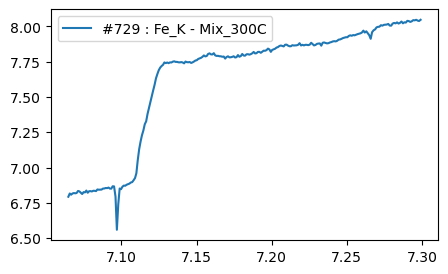

In [96]:
nxs = 729

# load whole nxs
filePath = [file_path for file_path in homePath.rglob(f"*{nxs}.nxs")][0]
spectrum = rn5.DataSet(filePath.name, filePath.parent)

# left and right trims are defined in the XASdict
trimL, trimR = XASdict[str(nxs)]['trim'][0], -1 -XASdict[str(nxs)]['trim'][1]

# extract trimmed data 
energy = spectrum.energy[trimL:trimR]
xbpm = spectrum.xbpm_cx1_i[trimL:trimR]
img_masked = spectrum.xpad140*(1-mask)

# integrate whole images then trim
roi0_masked = np.sum(img_masked, axis=(1, 2))[trimL:trimR]

# calculate absorption
XAS_masked = np.log(roi0_masked/xbpm)

label = f'#{nxs} : {XASdict[str(nxs)]['edge']} - {XASdict[str(nxs)]['label']}'

plt.figure(figsize=(5,3))
plt.plot(energy, XAS_masked, label = label)
plt.legend()
plt.show()

In [97]:
# instance larch object with energy and signal
data = Group(name='my group', energy=energy*1000, mu=XAS_masked)

normParams = {'pre1':-100, # the lower bond of the function to fit the pre-edge
         'pre2':-20, # the upper bond of the function to fit the pre-edge
         'norm1':10, # the lower bond of the function to fit the post-edge
         'norm2':200, # the upper bond of the function to fit the post-edge
         'nnorm':1, # degree for the polynomials
         'nvict':4}

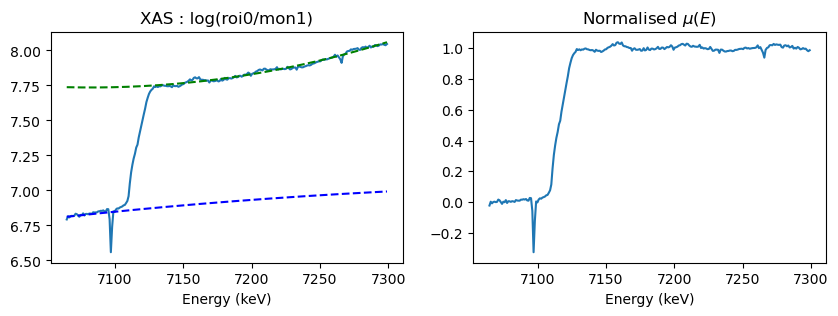

In [98]:
# tweak params, then copy it in the XASdict
normParams = {'pre1':-46, 'pre2':-3, 'norm1':30, 'norm2':300, 'nnorm':2, 'nvict':4}

pre_edge(data.energy, data.mu, group=data, **normParams)

fig, axes = plt.subplots(1, 2, figsize=(10, 3))

axes[0].plot(data.energy, data.mu, label='XAS')
axes[0].plot(data.energy, data.pre_edge,"b--")
axes[0].plot(data.energy, data.post_edge,"g--")
axes[0].set_xlabel("Energy (keV)")
axes[0].set_title("XAS : log(roi0/mon1)")

axes[1].plot(data.energy, data.flat, label='XAS')
#plt.plot(data.energy, data.xas, label='XAS')
axes[1].set_xlabel("Energy (keV)")
axes[1].set_title("Normalised $\mu(E)$")
plt.show()

In [55]:
pre_edge?

Signature: pre_edge(*args, **kwargs)
Docstring:
pre edge subtraction, normalization for XAFS

This performs a number of steps:
   1. determine E0 (if not supplied) from max of deriv(mu)
   2. fit a line of polymonial to the region below the edge
   3. fit a polymonial to the region above the edge
   4. extrapolate the two curves to E0 and take their difference
      to determine the edge jump

Arguments
----------
energy:  array of x-ray energies, in eV, or group (see note 1)
mu:      array of mu(E)
group:   output group
e0:      edge energy, in eV. If None, it will be determined here.
step:    edge jump.  If None, it will be determined here.
pre1:    low E range (relative to E0) for pre-edge fit
pre2:    high E range (relative to E0) for pre-edge fit
nvict:   energy exponent to use for pre-edg fit.  See Notes.
norm1:   low E range (relative to E0) for post-edge fit
norm2:   high E range (relative to E0) for post-edge fit
nnorm:   degree of polynomial (ie, nnorm+1 coefficients will be 

In [ ]:
'386'

In [53]:
nxs = 287

# load whole nxs
filePath = [file_path for file_path in homePath.rglob(f"*{nxs}.nxs")][0]
spectrum = rn5.DataSet(filePath.name, filePath.parent)

# left and right trims are defined in the XASdict
trimL, trimR = XASdict[str(nxs)]['trim'][0], -1 -XASdict[str(nxs)]['trim'][1]

# extract trimmed data 
energy = spectrum.energy[trimL:trimR]
mon1 = spectrum.xbpm_cx1_i[trimL:trimR]
img_masked = spectrum.xpad140*(1-mask)

# integrate whole images then trim
roi0_masked = np.sum(img_masked, axis=(1, 2))[trimL:trimR]

# calculate absorption
XAS_masked = np.log(roi0_masked/mon1)

# instance larch object with energy and signal
data = Group(name='my group', energy=energy*1000, mu=XAS_masked)

# normalize spectrum using larch function and predetermined set of params save in XASdict
pre_edge(data.energy, data.mu, group=data, **XASdict[str(nxs)]['normParams'])

data

Attribute,Type,Value
energy,ndarray,"shape=(248,), type=float64 range=[ 8301.90898: 8549.17654]"
mu,ndarray,"shape=(248,), type=float64 range=[ 7.96507608: 8.70157580]"
journal,Journal,"[('pre_edge_callargs', {'e0': None, 'step': None, 'nnorm': 1, 'nvict': 4, 'pre1': -100, 'pre2': -25, 'norm1': 10, 'norm2': 200, 'make_flat': True}, '2026-10-16T23:52:32.507224')]"
e0,float64,np.float64(8343.905414104156)
norm,ndarray,"shape=(248,), type=float64 range=[-0.01538029: 1.58490992]"
flat,ndarray,"shape=(248,), type=float64 range=[-0.01538029: 1.58441540]"
norm_poly,ndarray,"shape=(248,), type=float64 range=[-0.01538029: 1.58490992]"
flat_coefs,tuple,"(np.float64(-0.4012123258267719), np.float64(0.0001679324316701484), 0.0)"
flat_alt,ndarray,"shape=(248,), type=float64 range=[-0.01538029: 1.58441540]"
dmude,ndarray,"shape=(248,), type=float64 range=[-0.07858089: 0.23470292]"


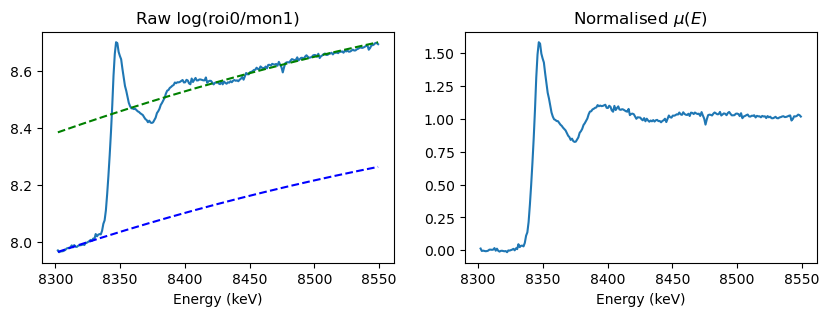

In [55]:
# plot raw and normaliezed data

fig, axes = plt.subplots(1, 2, figsize=(10, 3))

axes[0].plot(data.energy, data.mu, label='XAS')
axes[0].plot(data.energy, data.pre_edge,"b--")
axes[0].plot(data.energy, data.post_edge,"g--")
axes[0].set_xlabel("Energy (keV)")
axes[0].set_title("Raw log(roi0/mon1)")

axes[1].plot(data.energy, data.norm, label='XAS')
#plt.plot(data.energy, data.xas, label='XAS')
axes[1].set_xlabel("Energy (keV)")
axes[1].set_title("Normalised $\mu(E)$")
plt.show()

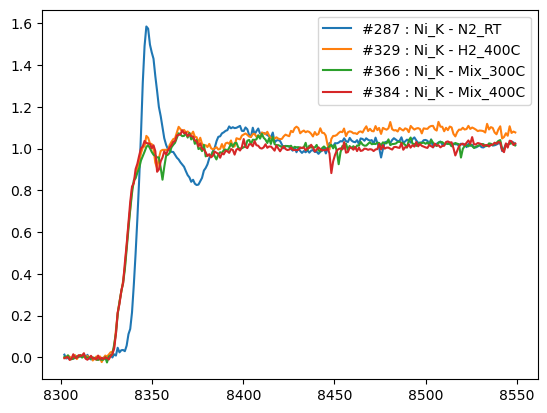

In [62]:
#NXStoPlot = [289, 331, 368, 386] # Co
NXStoPlot = [287, 329, 366, 384] # Ni

#fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for nxs in NXStoPlot:
    filePath = [file_path for file_path in homePath.rglob(f"*{nxs}.nxs")][0]
    spectrum = rn5.DataSet(filePath.name, filePath.parent)
    trimL, trimR = XASdict[str(nxs)]['trim'][0], -1 -XASdict[str(nxs)]['trim'][1]
    
    energy = spectrum.energy[trimL:trimR]
    mon1 = spectrum.xbpm_cx1_i[trimL:trimR]
    img_masked = spectrum.xpad140*(1-mask)
    roi0_masked = np.sum(img_masked, axis=(1, 2))[trimL:trimR]
    XAS_masked = np.log(roi0_masked/mon1)
    
    data = Group(name='my group', energy=energy*1000, mu=XAS_masked)
    pre_edge(data.energy, data.mu, group=data, **XASdict[str(nxs)]['normParams'])

    label = f'#{nxs} : {XASdict[str(nxs)]['edge']} - {XASdict[str(nxs)]['label']}'

    plt.plot(data.energy, data.norm, label=label)

plt.legend()

In [63]:
zip?

Init signature: zip(*iterables, strict=False)
Docstring:     
The zip object yields n-length tuples, where n is the number of iterables
passed as positional arguments to zip().  The i-th element in every tuple
comes from the i-th iterable argument to zip().  This continues until the
shortest argument is exhausted.

If strict is true and one of the arguments is exhausted before the others,
raise a ValueError.

   >>> list(zip('abcdefg', range(3), range(4)))
   [('a', 0, 0), ('b', 1, 1), ('c', 2, 2)]
Type:           type
Subclasses:     

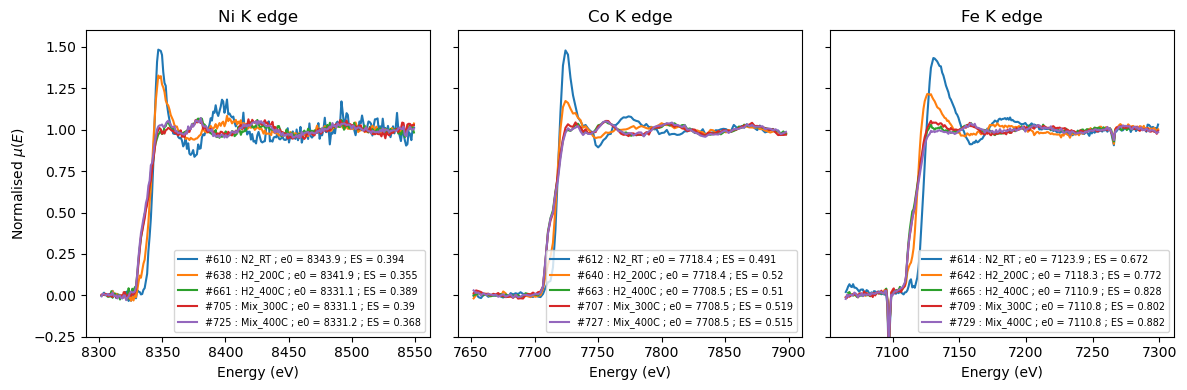

In [101]:
%matplotlib inline
plt.close()

nxstoPlot = [610, 612, 614, 638, 640, 642, 661, 663, 665, 705, 707, 709, 725, 727, 729]

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)

for nxs in nxstoPlot:
    filePath = [file_path for file_path in homePath.rglob(f"*{nxs}.nxs")][0]
    spectrum = rn5.DataSet(filePath.name, filePath.parent)
    trimL, trimR = XASdict[str(nxs)]['trim'][0], -1 -XASdict[str(nxs)]['trim'][1]
    
    energy = spectrum.energy[trimL:trimR]
    mon1 = spectrum.xbpm_cx1_i[trimL:trimR]
    img_masked = spectrum.xpad140*(1-mask)
    roi0_masked = np.sum(img_masked, axis=(1, 2))[trimL:trimR]
    XAS_masked = np.log(roi0_masked/mon1)
    
    data = Group(name='my group', energy=energy*1000, mu=XAS_masked)
    pre_edge(data.energy, data.mu, group=data, **XASdict[str(nxs)]['normParams'])

    label = f'#{nxs} : {XASdict[str(nxs)]['label']} ; e0 = {data.e0:.1f} ; ES = {data.edge_step:.3g}'
    
    if XASdict[str(nxs)]['edge'] == 'Ni_K':
        axes[0].plot(data.energy, data.flat, label=label)
    elif XASdict[str(nxs)]['edge'] == 'Co_K':
        axes[1].plot(data.energy, data.flat, label=label)
    elif XASdict[str(nxs)]['edge'] == 'Fe_K':
        axes[2].plot(data.energy, data.flat, label=label)
        

axes[0].legend(fontsize = 'x-small')
axes[0].set_xlabel('Energy (eV)')
axes[0].set_ylabel('Normalised $\mu(E)$')
axes[0].set_title("Ni K edge")
axes[0].set_ylim(-0.25,1.6)
axes[1].legend(fontsize = 'x-small')
axes[1].set_xlabel('Energy (eV)')
axes[1].set_title("Co K edge")
axes[2].legend(fontsize = 'x-small')
axes[2].set_xlabel('Energy (eV)')
axes[2].set_title("Fe K edge")

plt.tight_layout()

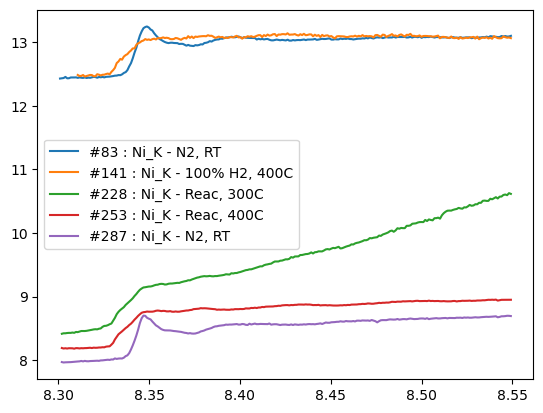

In [79]:
flagSave = False


NXStoPlot = [83, 141, 228, 253, 287] # Ni
NXStoPlot = [83, 141, 228, 253, 287] # Ni
#NXStoPlot = [89, 144, 232, 255] # Co
#NXStoPlot = [100, 147, 236, 257] # Fe


for nxs in NXStoPlot:
    filePath = [file_path for file_path in homePath.rglob(f"*{nxs}.nxs")][0]
    spectrum = rn5.DataSet(filePath.name, filePath.parent)
    energy = spectrum.energy
    mon0 = spectrum.imon0
    mon1 = spectrum.xbpm_cx1_i
    
    roi0 = np.sum(spectrum.xpad140, axis=(1, 2))
    roi0_masked = np.sum(spectrum.xpad140*(1-mask), axis=(1, 2))
    XAS = np.log(roi0/mon1)
    XAS_masked = np.log(roi0_masked/mon1)
    trimL, trimR = XASdict[str(nxs)]['trim'][0], -1 -XASdict[str(nxs)]['trim'][1]
    
    if flagSave:
        energy_trimmed, XAS_trimmed = energy[trimL:trimR], XAS_masked[trimL:trimR]
        data_to_save = np.column_stack((energy_trimmed, XAS_trimmed))
        output_filename = f"{nxs}_{filePath.name.split('_')[0]}_{XASdict[str(nxs)]['edge']}.txt" 
        np.savetxt(output_filename, data_to_save, header="Energy\tXAS", comments='', delimiter='\t')
    
    label = f'#{nxs} : {XASdict[str(nxs)]['edge']} - {XASdict[str(nxs)]['label']}'
    plt.plot(energy[trimL:trimR], XAS_masked[trimL:trimR], label = label)

plt.legend()

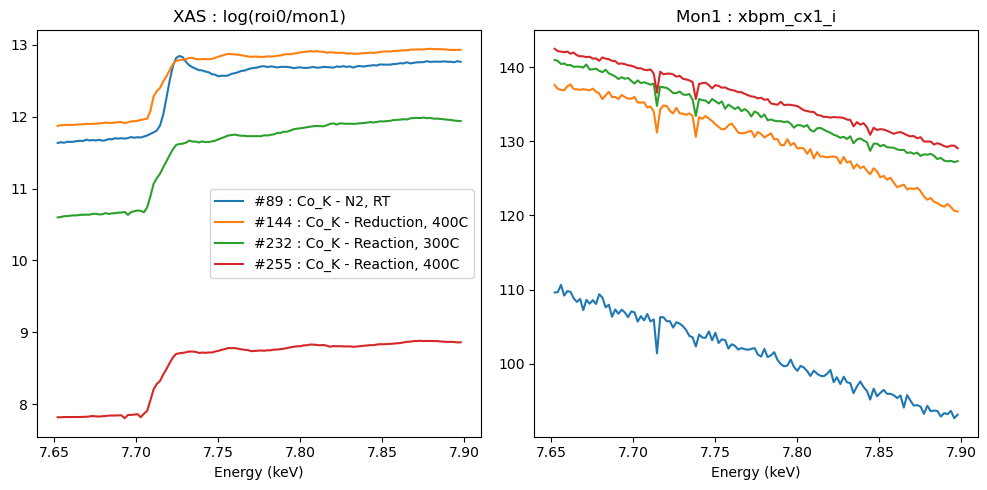

In [9]:
%matplotlib inline
plt.close()

NXStoPlot = [287, 329, 366] # Ni sample2
#NXStoPlot = [289, 331, 368] # Co sample2
#NXStoPlot = [83, 141, 228, 253, 287] # Ni
NXStoPlot = [89, 144, 232, 255] # Co
#NXStoPlot = [100, 147, 236] # Fe

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for nxs in NXStoPlot:
    filePath = [file_path for file_path in homePath.rglob(f"*{nxs}.nxs")][0]
    spectrum = rn5.DataSet(filePath.name, filePath.parent)
    energy = spectrum.energy
    mon0 = spectrum.imon0
    mon1 = spectrum.xbpm_cx1_i
    mon1_filt = savgol_filter(mon1, window_length=13, polyorder=3)
    gap = spectrum.gap
    bragg = spectrum.bragg

    roi0 = np.sum(spectrum.xpad140, axis=(1, 2))
    roi0_masked = np.sum(spectrum.xpad140*(1-mask), axis=(1, 2))
    XAS = np.log(roi0/mon1)
    XAS_masked = np.log(roi0_masked/mon1)
    
    XAS_mon = np.log(mon1/mon0)
    
    trimL, trimR = XASdict[str(nxs)]['trim'][0], -1 -XASdict[str(nxs)]['trim'][1]
    label = f'#{nxs} : {XASdict[str(nxs)]['edge']} - {XASdict[str(nxs)]['label']}'
    axes[0].plot(energy[trimL:trimR], XAS_masked[trimL:trimR], label = label)
    axes[0].legend()
    axes[0].set_xlabel("Energy (keV)")
    axes[0].set_title("XAS : log(roi0/mon1)")
    
    axes[1].plot(energy[trimL:trimR], mon1[trimL:trimR])
    axes[1].set_title("Mon1 : xbpm_cx1_i")
    axes[1].set_xlabel("Energy (keV)")

plt.tight_layout()

In [32]:
6.482600+0.02


6.502599999999999

In [34]:

21.5*np.sqrt(12)/np.sqrt(4)

np.float64(37.23909236273086)

In [67]:
1500*0.3

450.0

In [ ]:
SBS.a2scan(bragg, 13.784, 13.373, gap, 6.333, 6.503, 250, 2)


16.611112036367977


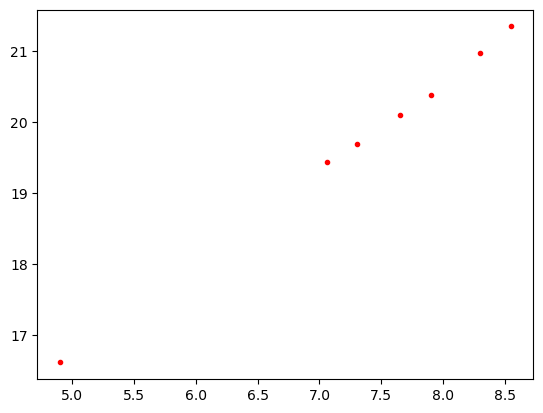

In [106]:
from numpy.polynomial import Polynomial
pitch = [16.61, 19.44, 19.69, 20.1, 20.39, 20.97, 21.35, 25.7]

energ = [4.9, 7.06, 7.3, 7.65, 7.9, 8.3, 8.55, 18.44]

line = Polynomial.fit(energ[:-1], pitch[:-1], deg=1, domain=[])
intercept, slope = line.coef
y2= 4.9*slope+intercept
print(y2)

plt.plot(energ[:-1], pitch[:-1], 'r.')


In [49]:
filePath = [file_path for file_path in homePath.rglob(f"*{nxs}.nxs")][0]
trimL, trimR = XASdict[str(nxs)]['trim'][0], -1 -XASdict[str(nxs)]['trim'][1]
spectrum = rn5.DataSet(filePath.name, filePath.parent)

energy = spectrum.energy[trimL:trimR]
mon0 = spectrum.imon0[trimL:trimR]
mon1 = spectrum.xbpm_cx1_i[trimL:trimR]
roi0 = np.sum(spectrum.xpad140, axis=(1, 2))[trimL:trimR]
roi0_masked = np.sum(spectrum.xpad140*(1-mask), axis=(1, 2))[trimL:trimR]

XAS = np.log(roi0/mon1)
XAS_masked = np.log(roi0_masked/mon1)

spectrum.attlist

['bragg',
 'gap',
 'mu_panda',
 'delta_panda',
 'gamma_panda',
 'xbpm_cx1_x',
 'xbpm_cx1_z',
 'xbpm_cx1_i',
 'h',
 'k',
 'l',
 'qpar',
 'qper',
 'q',
 'tc1',
 'xpad140',
 'roi0_s140',
 'roi1_s140',
 'roi2_s140',
 'roi3_s140',
 'roi4_s140',
 'roi0c_s140',
 'roi1c_s140',
 'roi2c_s140',
 'roi3c_s140',
 'roi4c_s140',
 'att_sbs_xpad',
 'imon0',
 'imon1',
 'imon2',
 'ln_i1_i0',
 'ln_cpt_i0',
 'ln_roi0s140_i0',
 'ln_roi0s140_xbpm',
 'att_mt',
 'mu',
 'delta',
 'gamma',
 'ssl3hp',
 'energy',
 'data_39_gap',
 'mono',
 'data_41_bragg',
 'pitch',
 'tz',
 'roll',
 'heater4',
 'integration_time',
 'sensorsRelTimestamps',
 'sensorsTimestamps',
 'trajectory_1_1_bragg',
 'trajectory_1_2_gap',
 'epoch',
 'attenuation',
 'mask_xpads140',
 'xpad_s140_ROIs',
 'attcoef',
 'attcoef_old']